# ELEVVO NLP INTERNSHIP
# Task 03: Fake News Detection

Install libraries

In [ ]:
!pip install -q datasets pandas numpy matplotlib seaborn scikit-learn nltk

Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk

from datasets import load_dataset
from nltk.corpus import stopwords

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

nltk.download('stopwords')

print("Libraries imported successfully!")

Libraries imported successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Load LIAR dataset

In [ ]:
dataset = load_dataset("tasksource/liar")

print(dataset)

print("\nDataset columns:")
print(dataset["train"].column_names)

print("\nDataset features:")
print(dataset["train"].features)

print("\nLabel names:")
label_names = dataset["train"].features["label"].names
print(label_names)

README.md:   0%|          | 0.00/291 [00:00<?, ?B/s]

default/test.parquet: reconstructing file:   0%|          |  0.00B /  159kB            

default/test.parquet: downloading bytes:           |  0.00B            

default/train.parquet: reconstructing file:   0%|          |  0.00B / 1.12MB            

default/train.parquet: downloading bytes:           |  0.00B            

default/validation.parquet: reconstructing file:   0%|          |  0.00B /  160kB            

default/validation.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/1283 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/10269 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1284 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['id', 'label', 'statement', 'subject', 'speaker', 'job_title', 'state_info', 'party_affiliation', 'barely_true_counts', 'false_counts', 'half_true_counts', 'mostly_true_counts', 'pants_on_fire_counts', 'context'],
        num_rows: 1283
    })
    train: Dataset({
        features: ['id', 'label', 'statement', 'subject', 'speaker', 'job_title', 'state_info', 'party_affiliation', 'barely_true_counts', 'false_counts', 'half_true_counts', 'mostly_true_counts', 'pants_on_fire_counts', 'context'],
        num_rows: 10269
    })
    validation: Dataset({
        features: ['id', 'label', 'statement', 'subject', 'speaker', 'job_title', 'state_info', 'party_affiliation', 'barely_true_counts', 'false_counts', 'half_true_counts', 'mostly_true_counts', 'pants_on_fire_counts', 'context'],
        num_rows: 1284
    })
})

Dataset columns:
['id', 'label', 'statement', 'subject', 'speaker', 'job_title', 'state_info', 'party_affiliation', 'barely_t

Convert Dataset into DataFrames

In [ ]:

import pandas as pd
import numpy as np

train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])
validation_df = pd.DataFrame(dataset["validation"])

print("Training Data Shape:", train_df.shape)
print("Testing Data Shape:", test_df.shape)
print("Validation Data Shape:", validation_df.shape)

print("\nFirst 5 Training Records:")
display(train_df[["statement", "label"]].head())


Training Data Shape: (10269, 14)
Testing Data Shape: (1283, 14)
Validation Data Shape: (1284, 14)

First 5 Training Records:


,statement,label
0,Says the Annies List political group supports ...,0
1,When did the decline of coal start? It started...,1
2,"Hillary Clinton agrees with John McCain ""by vo...",2
3,Health care reform legislation is likely to ma...,0
4,The economic turnaround started at the end of ...,1


Convert Labels into Fake and Real

In [ ]:

fake_labels = ["pants-fire", "false", "barely-true"]
real_labels = ["half-true", "mostly-true", "true"]

label_names = dataset["train"].features["label"].names

def convert_label(label):
    if isinstance(label, (int, np.integer)):
        label = label_names[int(label)]

    label = str(label).lower().strip()

    if label in fake_labels:
        return "Fake"
    elif label in real_labels:
        return "Real"
    else:
        return "Unknown"

train_df["category"] = train_df["label"].apply(convert_label)
test_df["category"] = test_df["label"].apply(convert_label)
validation_df["category"] = validation_df["label"].apply(convert_label)

print("Training Categories:")
print(train_df["category"].value_counts())

print("\nTesting Categories:")
print(test_df["category"].value_counts())


Training Categories:
category
Real    5772
Fake    4497
Name: count, dtype: int64

Testing Categories:
category
Real    727
Fake    556
Name: count, dtype: int64


Check Missing Values

In [ ]:

print("Missing Values in Training Data:")
print(train_df[["statement", "category"]].isnull().sum())

print("\nMissing Values in Testing Data:")
print(test_df[["statement", "category"]].isnull().sum())

train_df = train_df.dropna(subset=["statement", "category"])
test_df = test_df.dropna(subset=["statement", "category"])

train_df = train_df[train_df["category"] != "Unknown"].copy()
test_df = test_df[test_df["category"] != "Unknown"].copy()

print("\nTraining Data after Cleaning:", train_df.shape)
print("Testing Data after Cleaning:", test_df.shape)


Missing Values in Training Data:
statement    0
category     0
dtype: int64

Missing Values in Testing Data:
statement    0
category     0
dtype: int64

Training Data after Cleaning: (10269, 15)
Testing Data after Cleaning: (1283, 15)


Visualize Category Distribution

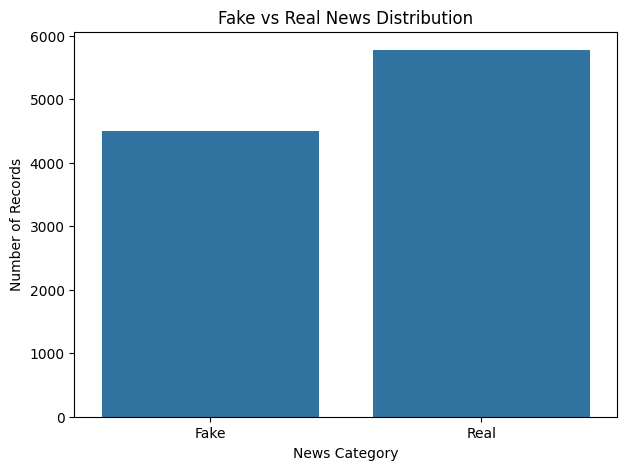

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=train_df, x="category")

plt.title("Fake vs Real News Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Records")
plt.show()


Text Cleaning

In [ ]:

import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

train_df["clean_statement"] = train_df["statement"].apply(clean_text)
test_df["clean_statement"] = test_df["statement"].apply(clean_text)

print("Original Statement:")
print(train_df["statement"].iloc[0])

print("\nCleaned Statement:")
print(train_df["clean_statement"].iloc[0])


Original Statement:
Says the Annies List political group supports third-trimester abortions on demand.

Cleaned Statement:
says the annies list political group supports thirdtrimester abortions on demand


Prepare Training and Testing Data

In [ ]:

X_train = train_df["clean_statement"]
y_train = train_df["category"]

X_test = test_df["clean_statement"]
y_test = test_df["category"]

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))


Training Samples: 10269
Testing Samples: 1283


Convert Text into Numerical Features (TF-IDF)

In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)


Training TF-IDF Shape: (10269, 20000)
Testing TF-IDF Shape: (1283, 20000)


Train Logistic Regression Model

In [ ]:

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


Evaluate Logistic Regression

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))


Logistic Regression Accuracy: 61.42 %

Classification Report:
              precision    recall  f1-score   support

        Fake       0.58      0.41      0.48       556
        Real       0.63      0.77      0.69       727

    accuracy                           0.61      1283
   macro avg       0.60      0.59      0.59      1283
weighted avg       0.61      0.61      0.60      1283



Confusion Matrix

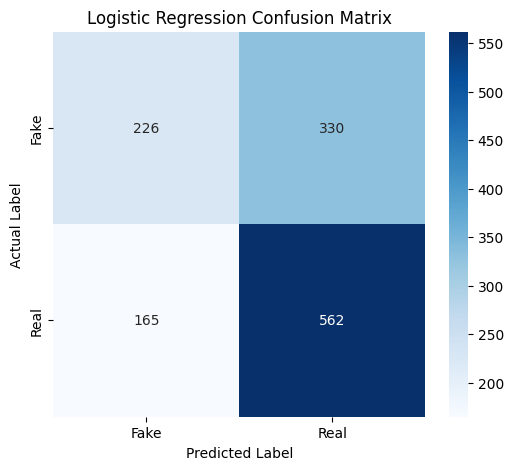

In [ ]:

plt.figure(figsize=(6, 5))

cm = confusion_matrix(y_test, lr_predictions, labels=["Fake", "Real"])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


Train Naive Bayes Model

In [ ]:

from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

print("Naive Bayes Model Trained Successfully!")


Naive Bayes Model Trained Successfully!


Evaluate Naive Bayes

In [ ]:

nb_accuracy = accuracy_score(y_test, nb_predictions)

print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, nb_predictions))


Naive Bayes Accuracy: 61.5 %

Classification Report:
              precision    recall  f1-score   support

        Fake       0.61      0.30      0.40       556
        Real       0.62      0.85      0.72       727

    accuracy                           0.61      1283
   macro avg       0.61      0.58      0.56      1283
weighted avg       0.61      0.61      0.58      1283



Compare Both Models

                 Model   Accuracy
0  Logistic Regression  61.418550
1          Naive Bayes  61.496493


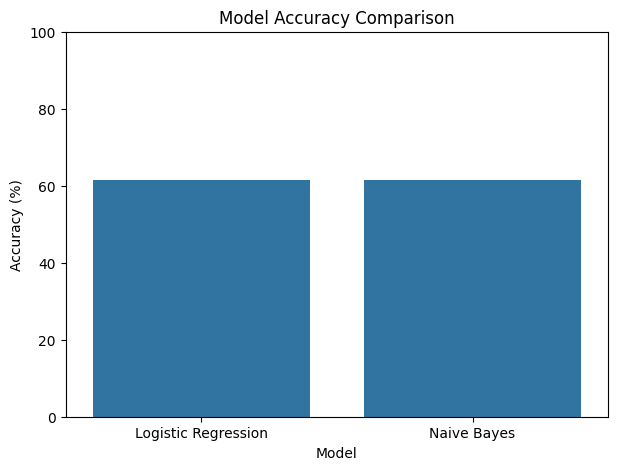

In [ ]:

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes"],
    "Accuracy": [lr_accuracy * 100, nb_accuracy * 100]
})

print(results)

plt.figure(figsize=(7, 5))

sns.barplot(data=results, x="Model", y="Accuracy")

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()


In [ ]:

def predict_news(news):
    cleaned_news = clean_text(news)
    news_vector = tfidf.transform([cleaned_news])

    prediction = lr_model.predict(news_vector)[0]
    probabilities = lr_model.predict_proba(news_vector)[0]

    confidence = max(probabilities) * 100

    print("News Statement:", news)
    print("Predicted Category:", prediction)
    print("Model Confidence:", round(confidence, 2), "%")

sample_news = "The government announced a new policy to improve education."

predict_news(sample_news)


News Statement: The government announced a new policy to improve education.
Predicted Category: Fake
Model Confidence: 52.27 %


Test Another News Statement

In [ ]:

sample_news_2 = "A completely fabricated statement with an unsupported claim."

predict_news(sample_news_2)


News Statement: A completely fabricated statement with an unsupported claim.
Predicted Category: Real
Model Confidence: 66.68 %


Final Project Summary

In [ ]:

print("=" * 45)
print("FAKE NEWS DETECTION - PROJECT SUMMARY")
print("=" * 45)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nLogistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

print("Naive Bayes Accuracy:",
      round(nb_accuracy * 100, 2), "%")

print("\nBest Performing Model:")

if lr_accuracy >= nb_accuracy:
    print("Logistic Regression")
else:
    print("Naive Bayes")

print("\nProject Completed Successfully!")


FAKE NEWS DETECTION - PROJECT SUMMARY
Training Records: 10269
Testing Records: 1283

Logistic Regression Accuracy: 61.42 %
Naive Bayes Accuracy: 61.5 %

Best Performing Model:
Naive Bayes

Project Completed Successfully!
